In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [97]:
df = pd.read_csv("C:\\Users\\banda\\OneDrive\\Desktop\\100-Days-Machine-Learning\\House Price Prediction\\House Price Prediction Dataset.csv")

In [98]:
df.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [8]:
df.shape

(2000, 10)

In [9]:
df.isnull().sum()

Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

C:\Users\banda\AppData\Local\Temp\ipykernel_3568\2751140939.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Bathrooms"])


<Axes: xlabel='Bathrooms', ylabel='Density'>

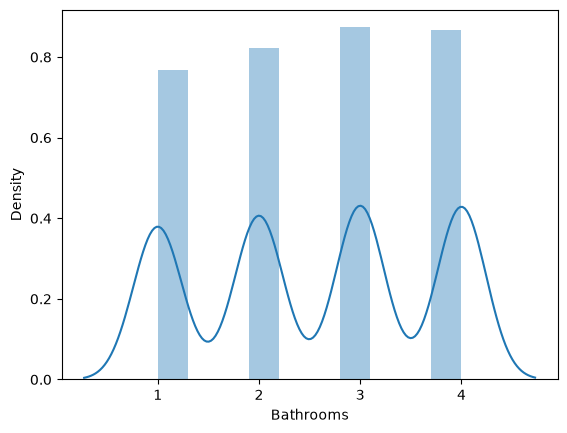

In [12]:
sns.distplot(df["Bathrooms"])

<Axes: xlabel='YearBuilt', ylabel='Price'>

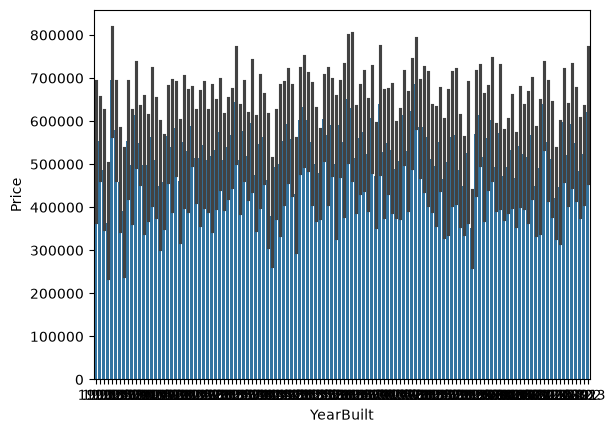

In [20]:
sns.barplot(data=df,x="YearBuilt",y="Price")

In [24]:
df["YearBuilt"].unique()

np.int64(1947)

In [28]:
df["Area"].nunique()

1622

<Axes: xlabel='Floors', ylabel='Price'>

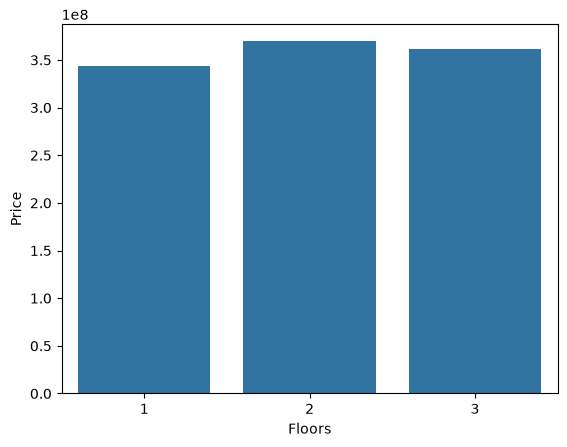

In [39]:
floor_price = df.groupby("Floors",as_index=False)["Price"].sum()
sns.barplot(data = floor_price,x="Floors",y="Price")

In [33]:
df["Location"].unique()

<ArrowStringArray>
['Downtown', 'Suburban', 'Urban', 'Rural']
Length: 4, dtype: str

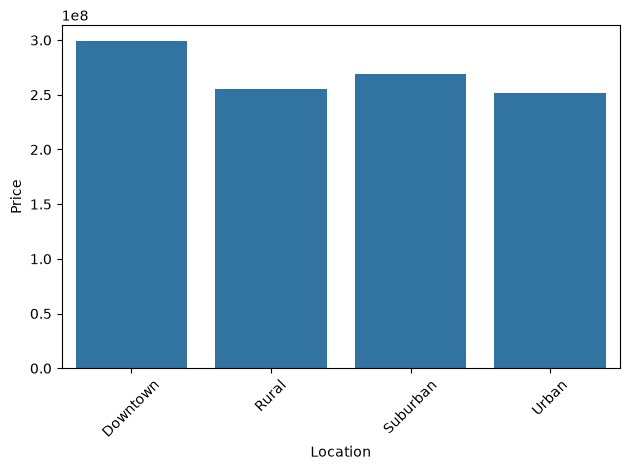

In [40]:
location_price = df.groupby("Location", as_index=False)["Price"].sum()

sns.barplot(data=location_price, x="Location", y="Price")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
df.columns

Index(['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt',
       'Location', 'Condition', 'Garage', 'Price'],
      dtype='str')

In [41]:
df["Garage"].unique()

<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

<Axes: xlabel='Garage'>

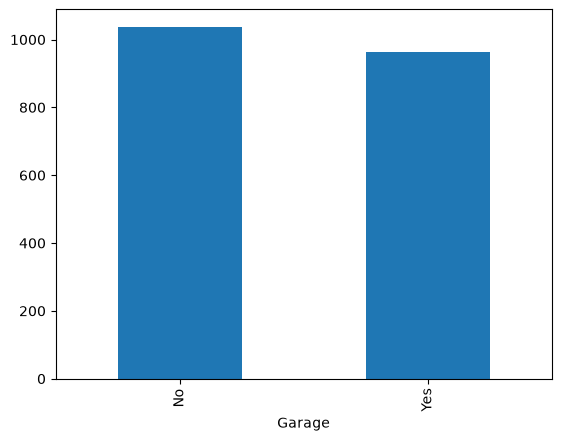

In [43]:
df["Garage"].value_counts().plot(kind="bar")

In [46]:
garage_price = df.groupby("Garage",as_index=False)["Price"].sum()

In [47]:
garage_price

,Garage,Price
0,No,557323687
1,Yes,518030023


C:\Users\banda\AppData\Local\Temp\ipykernel_3568\941010651.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Price"])


<Axes: xlabel='Price', ylabel='Density'>

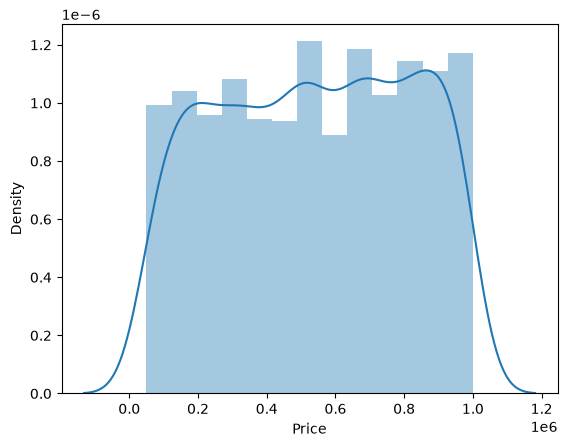

In [48]:
sns.distplot(df["Price"])

In [54]:
numerical_features = [feature for feature in df.columns if feature!='Id' and df[feature].dtypes!="O" and df[feature].dtypes!="str" ]

In [56]:
numerical_features

['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Price']

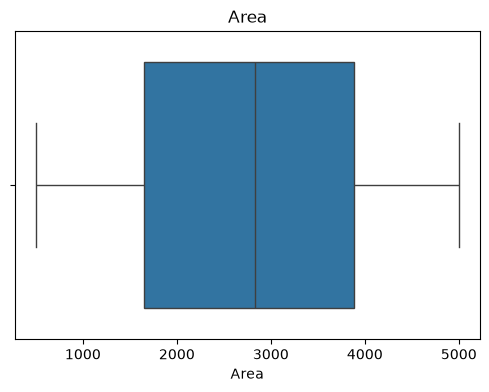

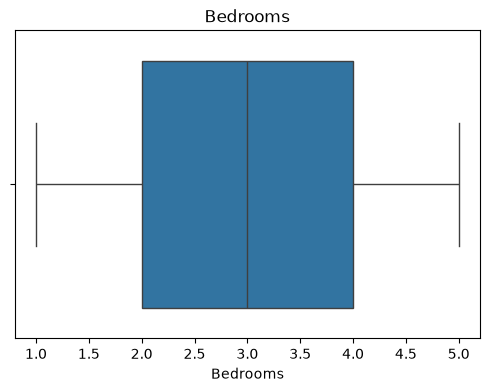

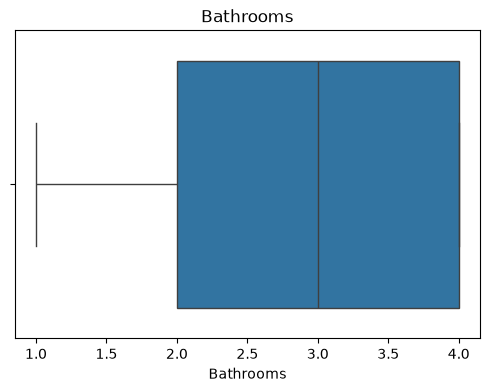

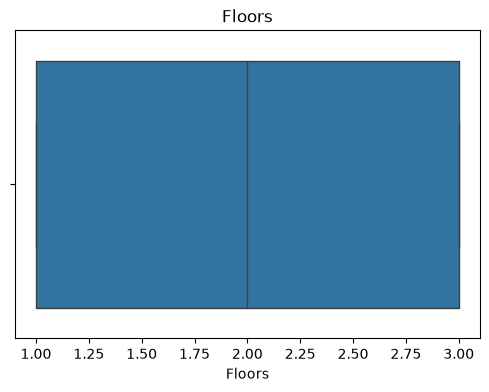

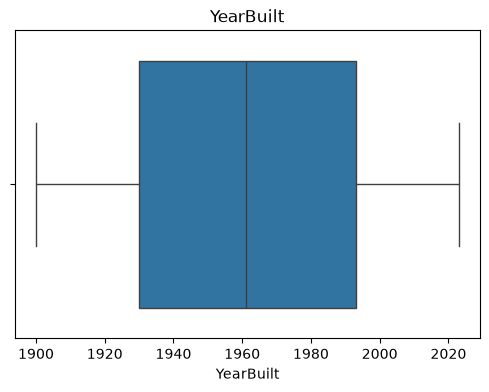

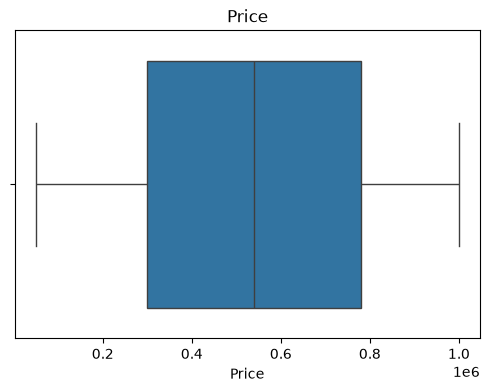

In [58]:
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numerical_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df[feature])
    plt.title(feature)
    plt.show()

In [90]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 184.3 KB


In [104]:
df["Condition"].unique()

<ArrowStringArray>
['Excellent', 'Good', 'Fair', 'Poor']
Length: 4, dtype: str

In [103]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer

In [115]:
transformer = ColumnTransformer(transformers=[
    ('tnf1',OrdinalEncoder(categories=[["Poor","Fair","Good","Excellent"],["No","Yes"]]),["Condition","Garage"]),
    ('tnf2',OneHotEncoder(sparse_output=False,drop='first'),['Location'])],
    remainder="passthrough")
    

In [121]:
result = transformer.fit_transform(df)
columns = transformer.get_feature_names_out()
df_transformed = pd.DataFrame(result, columns=columns)

In [123]:
df_transformed.head()

,tnf1__Condition,tnf1__Garage,tnf2__Location_Rural,tnf2__Location_Suburban,tnf2__Location_Urban,remainder__Id,remainder__Area,remainder__Bedrooms,remainder__Bathrooms,remainder__Floors,remainder__YearBuilt,remainder__Price
0,3.0,0.0,0.0,0.0,0.0,1.0,1360.0,5.0,4.0,3.0,1970.0,149919.0
1,3.0,0.0,0.0,0.0,0.0,2.0,4272.0,5.0,4.0,3.0,1958.0,424998.0
2,2.0,0.0,0.0,0.0,0.0,3.0,3592.0,2.0,2.0,3.0,1938.0,266746.0
3,1.0,1.0,0.0,1.0,0.0,4.0,966.0,4.0,2.0,2.0,1902.0,244020.0
4,1.0,1.0,0.0,0.0,0.0,5.0,4926.0,1.0,4.0,2.0,1975.0,636056.0


In [130]:
df_transformed.drop("remainder__Id",axis=1,inplace=True)

In [139]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df_transformed.iloc[:,0:10],df.iloc[:,-1],test_size=0.3,random_state=42)


In [140]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ -3281.55, 3304.47, -5010.68,...,-11360.82, 26501.4 , 51.91]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['tnf1__Condition','tnf1__Garage','tnf2__Location_Rural',..., 'remainder__Bathrooms','remainder__Floors','remainder__YearBuilt']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.091e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)


In [135]:
df_transformed.shape

(2000, 11)

In [153]:
y_pred = lr.predict(X_test)

In [154]:
y_test

1860    514764
353     694256
1333     66375
905     650243
1289    223285
         ...  
148     406043
1554    464562
1956    303730
925     171449
942     160401
Name: Price, Length: 600, dtype: int64

In [155]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [156]:
mean_absolute_error(y_test,y_pred)

246079.2788189591

In [157]:
r2_score(y_test,y_pred)

-0.012761973758626421

In [158]:
mean_squared_error(y_test,y_pred)

79542764083.00333

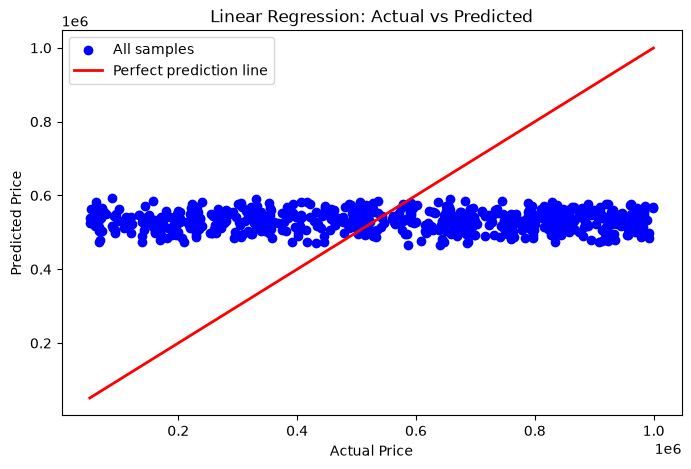

In [159]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Predict all test samples
y_pred = lr.predict(X_test)

# Scatter plot of actual and predicted prices
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, color="blue", label="All samples")

# Red reference line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linewidth=2,
    label="Perfect prediction line"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.show()